In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
ah = pd.read_csv('AmesHousing.csv', sep='\t')
ah.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [37]:
missing_data = ah.isnull().sum()
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)
print(missing_data)

Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
BsmtFin SF 1         1
BsmtFin SF 2         1
Electrical           1
Total Bsmt SF        1
Bsmt Unf SF          1
Garage Area          1
Garage Cars          1
dtype: int64


<Axes: xlabel='Has_Pool'>

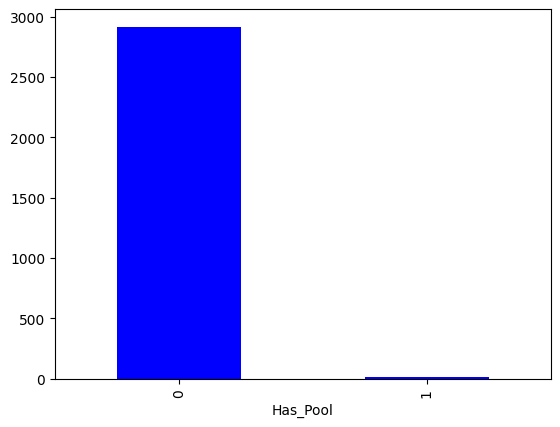

In [33]:
ah['Pool QC'] = ah['Pool QC'].fillna("None")

ah['Pool QC'].value_counts().plot(kind='bar', color='blue')

# we can observe that we have way too many missing values in 'Pool QC', so we will replace it with "Has_Pool"

ah["Has_Pool"] = (ah["Pool QC"] != "None").astype(int)

ah = ah.drop(columns=["Pool QC"])

ah['Has_Pool'].value_counts().plot(kind='bar', color='blue')


<Axes: xlabel='Lot Shape'>

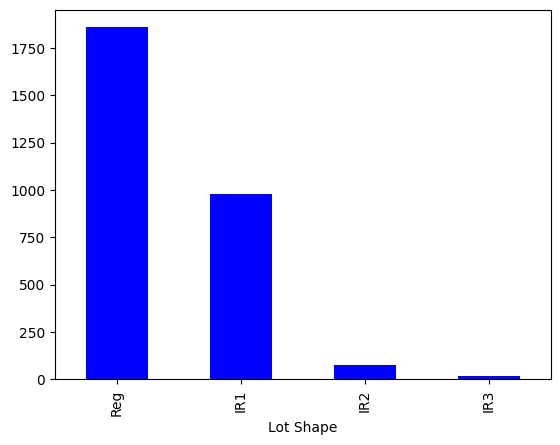

In [ ]:
ah['Lot Shape'].value_counts().plot(kind='bar', color='blue')

# we will unify all irregular shapes in one category called "Irregular" and keep the regular shapes as they are

ah['Has_Irregular_Lot_Shape'] = ah['Lot Shape'].apply(lambda x: 1 if x in ['IR1', 'IR2', 'IR3'] else 0)
ah = ah.drop(columns=["Lot Shape"])

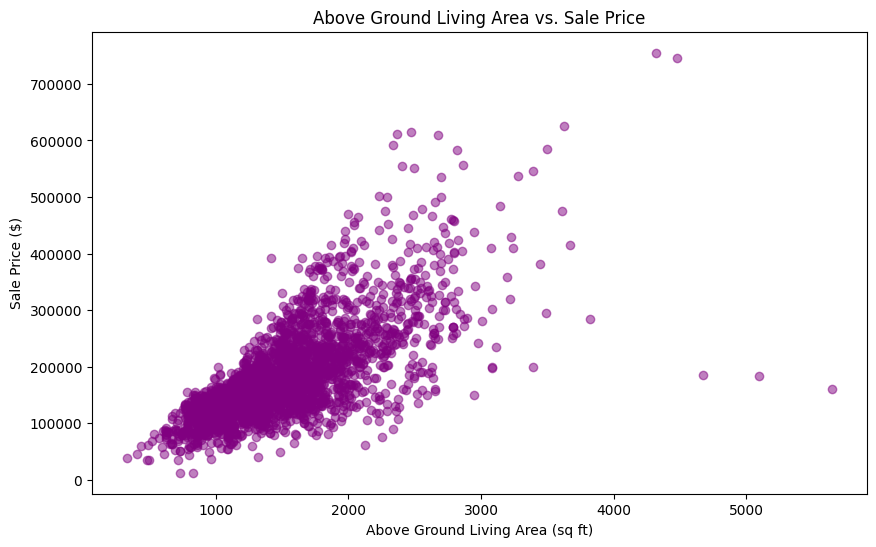

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(x=ah['Gr Liv Area'], y=ah['SalePrice'], alpha=0.5, color='purple')

plt.title('Above Ground Living Area vs. Sale Price')
plt.xlabel('Above Ground Living Area (sq ft)')
plt.ylabel('Sale Price ($)')

plt.show()

# we see a trend between the above ground living area and the sale price, but there are some outliers that we will have to remove

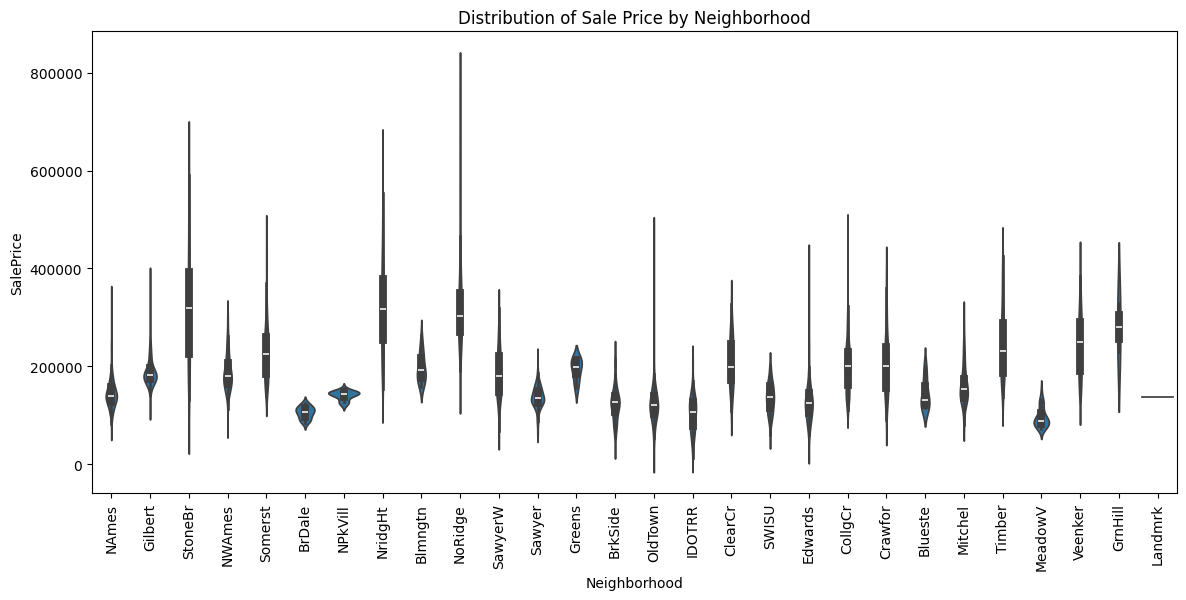

Neighborhood
NAmes      443
CollgCr    267
OldTown    239
Edwards    194
Somerst    182
NridgHt    166
Gilbert    165
Sawyer     151
NWAmes     131
SawyerW    125
Mitchel    114
BrkSide    108
Crawfor    103
IDOTRR      93
Timber      72
NoRidge     71
StoneBr     51
SWISU       48
ClearCr     44
MeadowV     37
BrDale      30
Blmngtn     28
Veenker     24
NPkVill     23
Blueste     10
Greens       8
GrnHill      2
Landmrk      1
Name: count, dtype: int64


In [43]:
plt.figure(figsize=(14, 6))
sns.violinplot(x='Neighborhood', y='SalePrice', data=ah)
plt.xticks(rotation=90)
plt.title('Distribution of Sale Price by Neighborhood')
plt.show()

print(ah['Neighborhood'].value_counts())

# We will replace "Neighborhood" with One Hot Encoding. We will split it into 3 categories: "Cheap", "Modest", "Expensive" based on the average sale price in each neighborhood.

# Some neighborhoods have a very diverse distribution, so we will remove outliers for a more accurate representation of the average sale price in each neighborhood

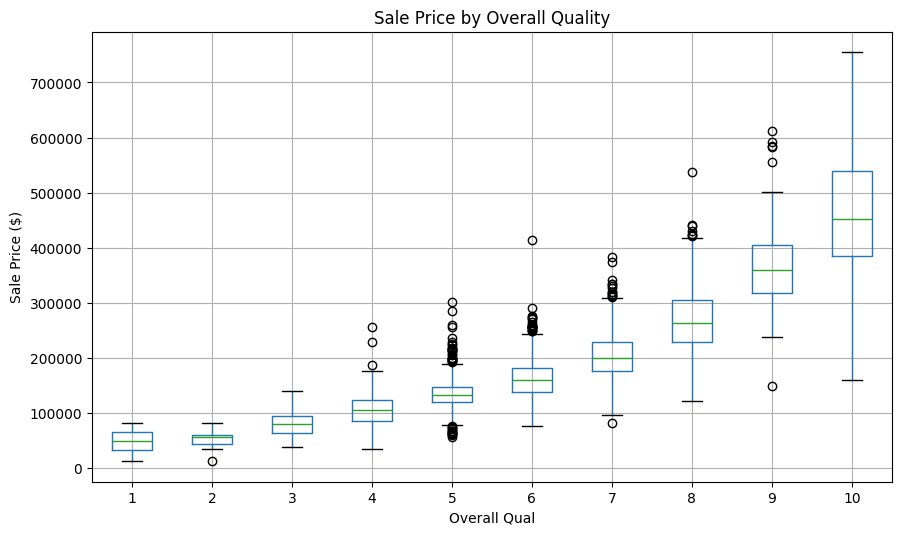

In [45]:
ah.boxplot(column='SalePrice', by='Overall Qual', figsize=(10, 6))
plt.title('Sale Price by Overall Quality')
plt.suptitle('')
plt.ylabel('Sale Price ($)')
plt.show()

# we can observe that "Overall Qual" is a highly reliable ordinal feature that has a strict positive correlation with  the sale price

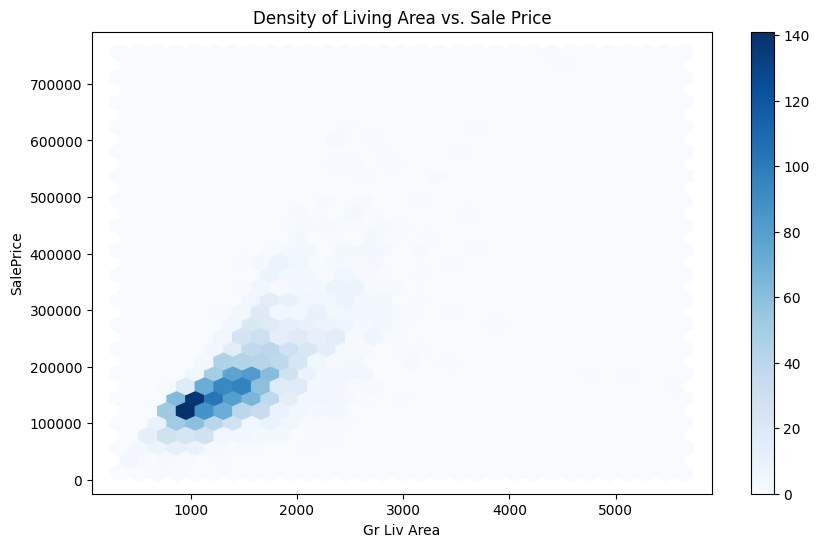

In [46]:
ah.plot(kind='hexbin', x='Gr Liv Area', y='SalePrice', gridsize=30, cmap='Blues', figsize=(10, 6))
plt.title('Density of Living Area vs. Sale Price')
plt.show()

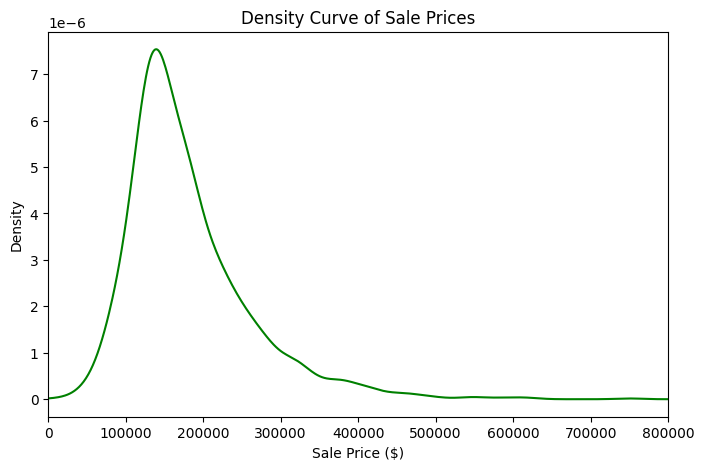

In [ ]:
ah['SalePrice'].plot(kind='kde', figsize=(8, 5), color='green')
plt.title('Density Curve of Sale Prices')
plt.xlabel('Sale Price ($)')
plt.xlim(0, 800000) 
plt.show()

# we can observe that the sale price distribution is right-skewed

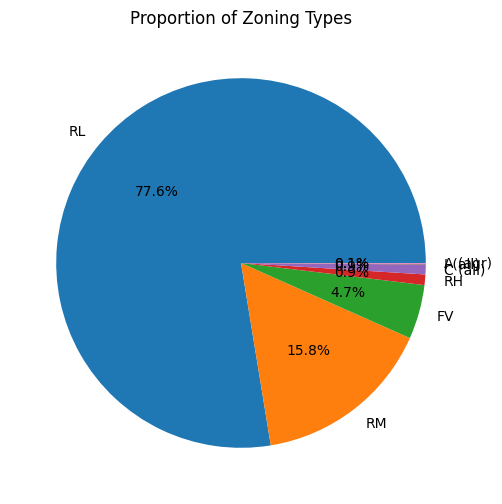

In [ ]:
ah['MS Zoning'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(6, 6))
plt.title('Proportion of Zoning Types')
plt.ylabel('') 
plt.show()

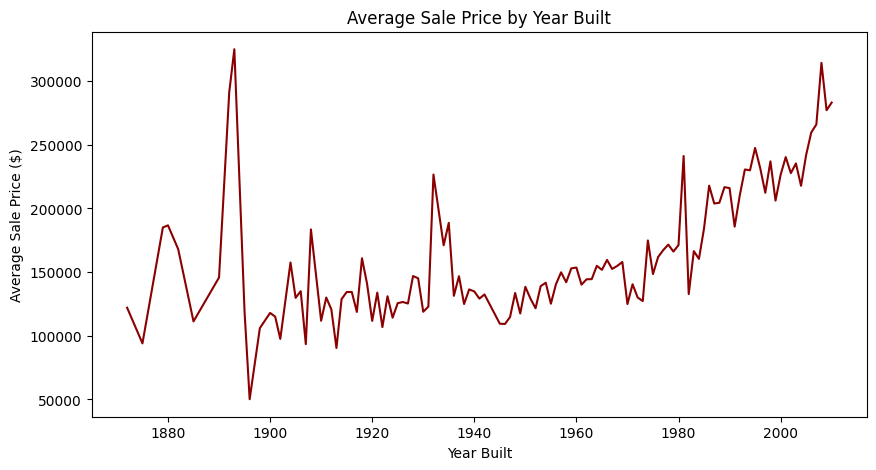

In [ ]:
avg_price_by_year = ah.groupby('Year Built')['SalePrice'].mean()

avg_price_by_year.plot(kind='line', figsize=(10, 5), color='darkred')
plt.title('Average Sale Price by Year Built')
plt.ylabel('Average Sale Price ($)')
plt.show()